# ORION ENTERPRISES
# Business Analytics and BI Reporting
# Exploratory Data Analysis


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned dataset

In [4]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Orion Enterprises/orion_solar_operations_cleaned.csv")

# Convert date

In [5]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully
Rows: 3900
Columns: 29


# 1. DATASET OVERVIEW

In [6]:
print("Dataset Shape:", df.shape)


Dataset Shape: (3900, 29)


In [7]:
print("\nData Types:")
print(df.dtypes)


Data Types:
transaction_id                         object
transaction_date               datetime64[ns]
customer_id                            object
customer_type                          object
customer_city                          object
sales_region                           object
sales_channel                          object
product_category                       object
product_name                           object
brand                                  object
unit                                   object
quantity                                int64
unit_price_inr                          int64
gross_sales_inr                       float64
discount_pct                          float64
discount_amount_inr                   float64
net_sales_inr                         float64
gst_amount_inr_synthetic              float64
invoice_value_inr_synthetic           float64
payment_method                         object
payment_status                         object
shipping_type        

In [8]:
print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing Values:
installation_status    2272
dtype: int64


In [9]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [10]:
print("\nUnique Customers:", df["customer_id"].nunique())


Unique Customers: 767


In [11]:
print("\nDate Range:")
print("Start:", df["transaction_date"].min())
print("End:", df["transaction_date"].max())


Date Range:
Start: 2025-04-01 00:00:00
End: 2026-03-31 00:00:00


# 2. DESCRIPTIVE STATISTICS

In [13]:
numeric_columns = [
    "quantity",
    "unit_price_inr",
    "gross_sales_inr",
    "discount_pct",
    "discount_amount_inr",
    "net_sales_inr",
    "gst_amount_inr_synthetic",
    "invoice_value_inr_synthetic",
    "lead_time_days",
    "previous_orders"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,3900.0,11.605897,13.362882,1.0,4.000,7.0,14.0000,180.00
unit_price_inr,3900.0,11336.356410,12682.665409,40.0,1840.000,12160.0,14430.0000,69030.00
gross_sales_inr,3900.0,104024.479487,160199.114266,100.0,7157.500,50780.0,131250.0000,2275230.00
discount_pct,3900.0,4.484103,3.071329,0.0,2.000,5.0,7.0000,13.50
discount_amount_inr,3900.0,5521.229859,11205.439881,0.0,106.875,1386.5,6089.0000,130914.00
net_sales_inr,3900.0,98503.249628,150653.878134,100.0,6848.850,48890.0,125504.6000,2195596.95
gst_amount_inr_synthetic,3900.0,11820.389936,18078.465309,12.0,821.860,5866.8,15060.5525,263471.63
invoice_value_inr_synthetic,3900.0,110323.639564,168732.343443,112.0,7670.710,54756.8,140565.1525,2459068.58
lead_time_days,3900.0,3.331795,1.844191,1.0,2.000,3.0,5.0000,10.00
previous_orders,3900.0,8.261538,7.325244,0.0,3.000,6.0,11.0000,41.00


# 3. OVERALL SALES PERFORMANCE

In [14]:
total_sales = df["net_sales_inr"].sum()

total_orders = df["transaction_id"].nunique()

total_units = df["quantity"].sum()

average_order_value = df["net_sales_inr"].mean()

print(f"Total Net Sales: ₹{total_sales:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Units Sold: {total_units:,}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")

Total Net Sales: ₹384,162,673.55
Total Orders: 3,900
Total Units Sold: 45,263
Average Order Value: ₹98,503.25


# 4. MONTHLY SALES TREND

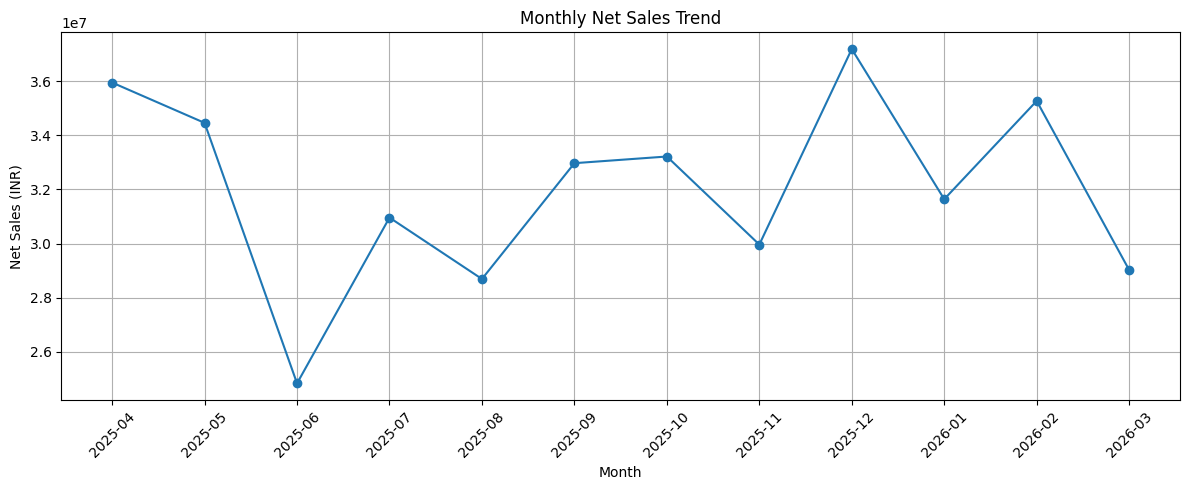

In [15]:
monthly_sales = (
    df.groupby(df["transaction_date"].dt.to_period("M"))
      ["net_sales_inr"]
      .sum()
      .reset_index()
)

monthly_sales["transaction_date"] = (
    monthly_sales["transaction_date"].astype(str)
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["transaction_date"],
    monthly_sales["net_sales_inr"],
    marker="o"
)

plt.title("Monthly Net Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

# 5. PRODUCT CATEGORY ANALYSIS

product_category
PV Module             2.565602e+08
Inverter              7.064018e+07
Mounting Structure    3.013362e+07
Battery               1.547441e+07
ACDB/DCDB             6.665159e+06
Electrical BOS        4.689103e+06
Name: net_sales_inr, dtype: float64


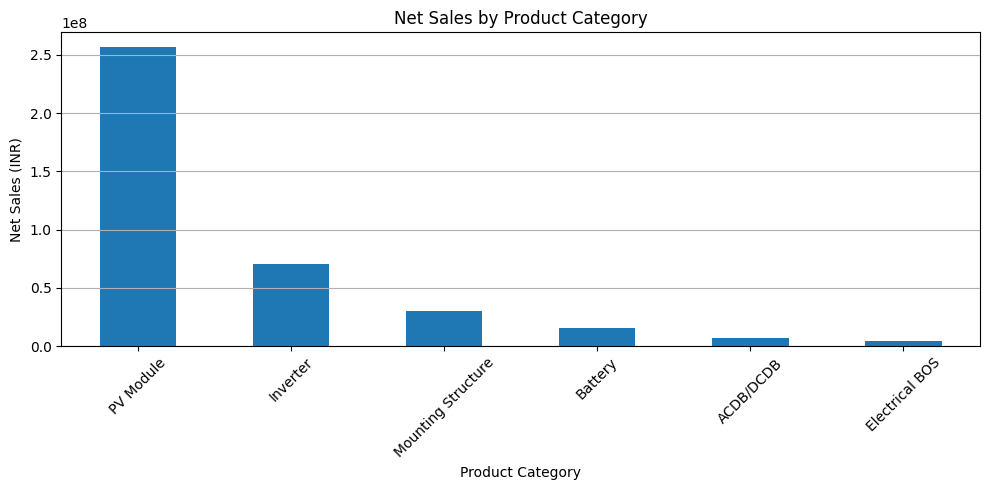

In [16]:
category_sales = (
    df.groupby("product_category")["net_sales_inr"]
      .sum()
      .sort_values(ascending=False)
)

print(category_sales)

plt.figure(figsize=(10, 5))

category_sales.plot(kind="bar")

plt.title("Net Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

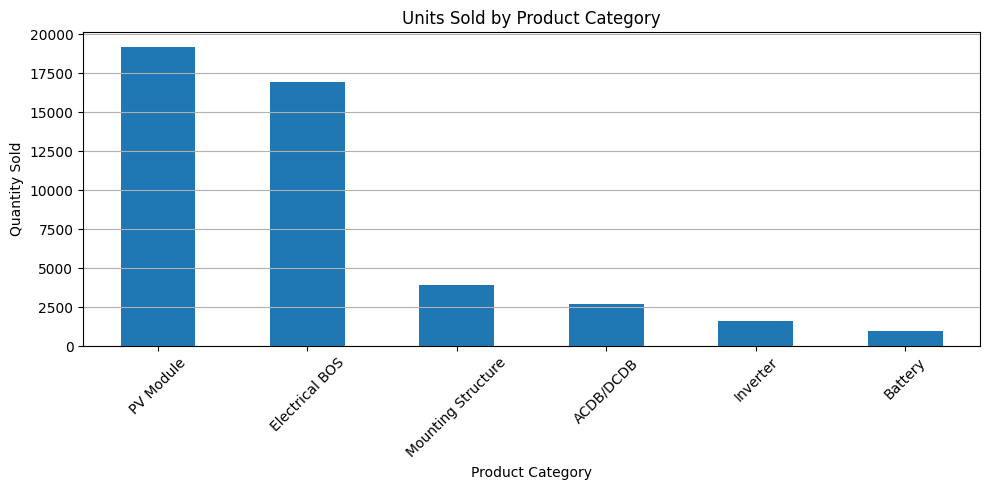

In [17]:
category_quantity = (
    df.groupby("product_category")["quantity"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

category_quantity.plot(kind="bar")

plt.title("Units Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

# 6. TOP PRODUCTS

product_name
Mono PERC 540W Solar Module       87644604.60
Mono PERC 545W Solar Module       70267954.95
TOPCon 580W Solar Module          50146830.55
TOPCon 575W Solar Module          48500816.50
3kW On-Grid Solar Inverter        25378881.00
5kW Hybrid Solar Inverter         22991158.40
5kW On-Grid Solar Inverter        22270145.50
Rooftop GI Mounting Structure     13102027.70
Aluminium Rooftop Mounting Kit    10166066.60
SF Tubular Solar Battery 150Ah     8773150.70
Name: net_sales_inr, dtype: float64


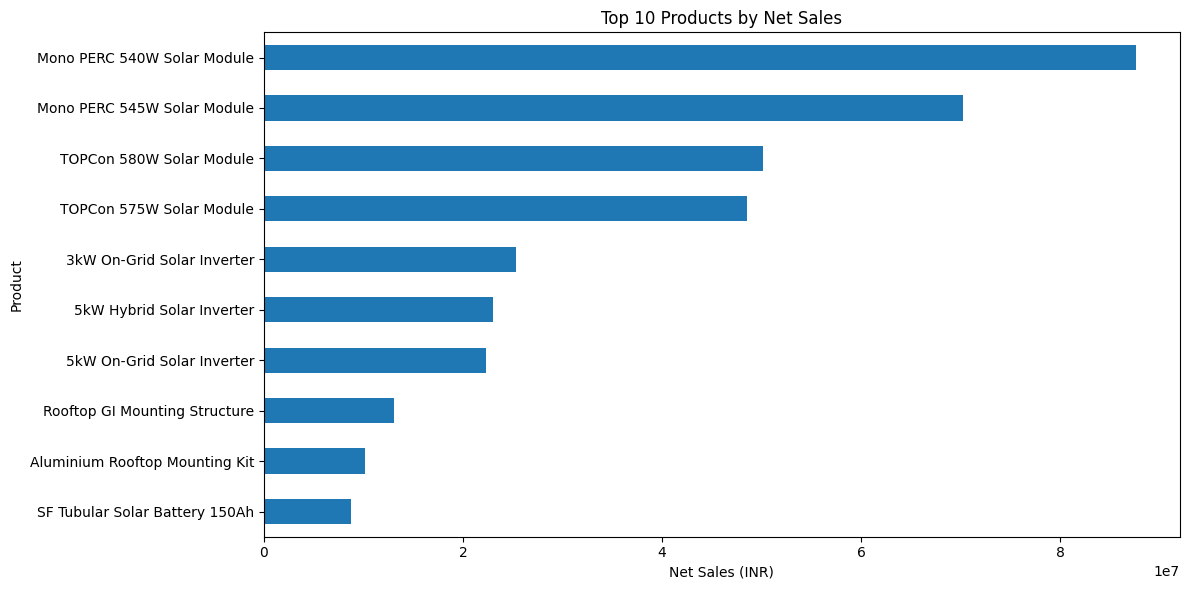

In [18]:
top_products = (
    df.groupby("product_name")["net_sales_inr"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_products)

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Net Sales")
plt.xlabel("Net Sales (INR)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

# 7. BRAND ANALYSIS

brand
Waaree          1.837944e+08
Adani Solar     1.434059e+08
Orion           4.148788e+07
SF Batteries    1.547441e+07
Name: net_sales_inr, dtype: float64


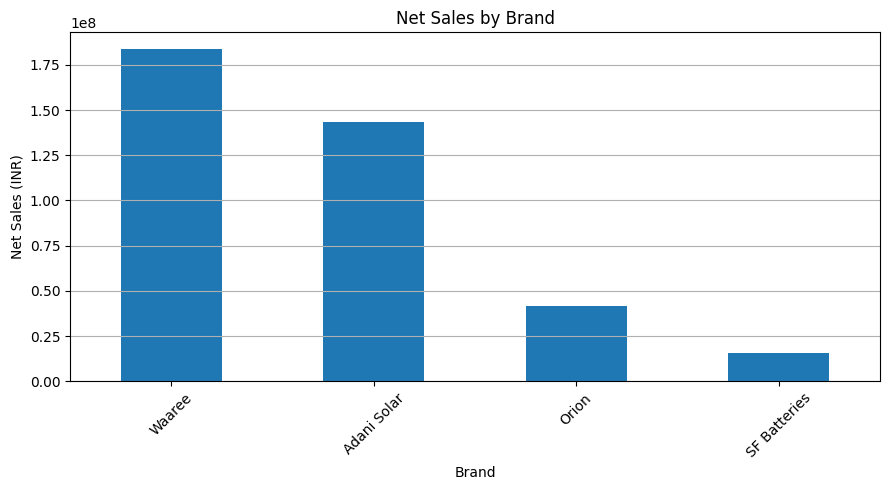

In [19]:
brand_sales = (
    df.groupby("brand")["net_sales_inr"]
      .sum()
      .sort_values(ascending=False)
)

print(brand_sales)

plt.figure(figsize=(9, 5))

brand_sales.plot(kind="bar")

plt.title("Net Sales by Brand")
plt.xlabel("Brand")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

# 8. CUSTOMER TYPE ANALYSIS

customer_type
Dealer         2.397745e+08
Installer      1.092656e+08
Residential    3.512265e+07
Name: net_sales_inr, dtype: float64


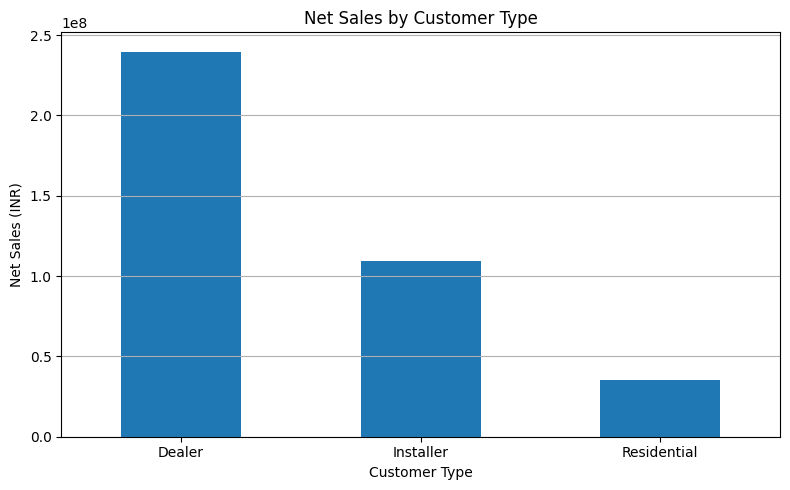

In [21]:
customer_type_sales = (
    df.groupby("customer_type")["net_sales_inr"]
      .sum()
      .sort_values(ascending=False)
)

print(customer_type_sales)

plt.figure(figsize=(8, 5))

customer_type_sales.plot(kind="bar")

plt.title("Net Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

# 9. SALES CHANNEL ANALYSIS


In [22]:
channel_analysis = (
    df.groupby("sales_channel")
      .agg(
          orders=("transaction_id", "nunique"),
          units=("quantity", "sum"),
          net_sales=("net_sales_inr", "sum")
      )
      .sort_values("net_sales", ascending=False)
)

print(channel_analysis)

                      orders  units     net_sales
sales_channel                                    
B2B Dealer              1760  28093  2.397745e+08
Rooftop Installation    1278  13080  1.092656e+08
Residential Rooftop      862   4090  3.512265e+07


# 10. GEOGRAPHICAL ANALYSIS

customer_city
Amravati      1.345231e+08
Akola         5.623809e+07
Yavatmal      4.387961e+07
Nagpur        3.664165e+07
Wardha        2.465472e+07
Buldhana      2.368221e+07
Nashik        2.027679e+07
Pune          1.809971e+07
Washim        1.525410e+07
Chandrapur    1.091269e+07
Name: net_sales_inr, dtype: float64


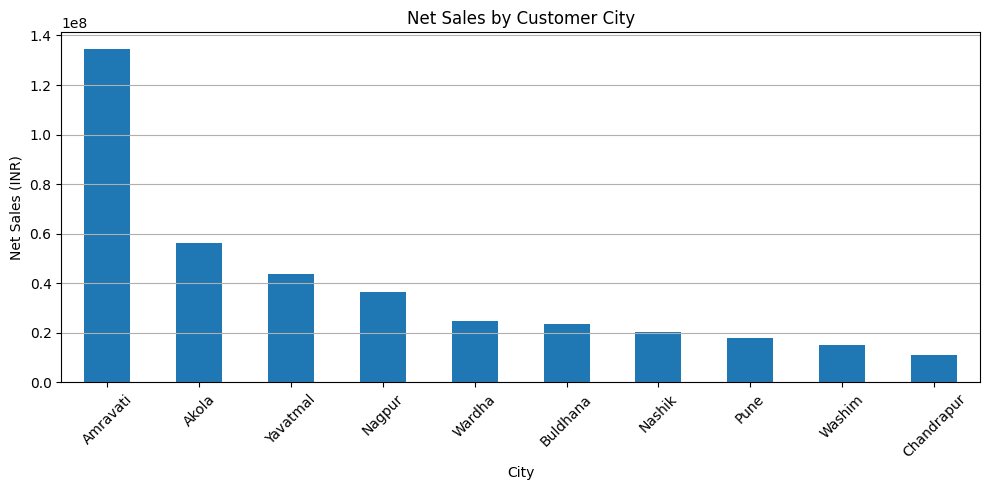

In [23]:
city_sales = (
    df.groupby("customer_city")["net_sales_inr"]
      .sum()
      .sort_values(ascending=False)
)

print(city_sales)

plt.figure(figsize=(10, 5))

city_sales.plot(kind="bar")

plt.title("Net Sales by Customer City")
plt.xlabel("City")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

# 11. CUSTOMER ANALYSIS

In [24]:
customer_sales = (
    df.groupby("customer_id")["net_sales_inr"]
      .sum()
      .sort_values(ascending=False)
)

print("Top 10 Customers:")
print(customer_sales.head(10))

Top 10 Customers:
customer_id
ORN-CUST-0317    4636077.60
ORN-CUST-0526    4087899.95
ORN-CUST-0131    3771859.75
ORN-CUST-0244    3669092.75
ORN-CUST-0052    3449226.15
ORN-CUST-0414    3220750.70
ORN-CUST-0080    3192885.90
ORN-CUST-0411    3052713.85
ORN-CUST-0056    2753891.10
ORN-CUST-0318    2722053.00
Name: net_sales_inr, dtype: float64


In [25]:
customer_frequency = (
    df.groupby("customer_id")
      .size()
      .sort_values(ascending=False)
)

repeat_customers = customer_frequency[
    customer_frequency > 1
]

print("Total Customers:", len(customer_frequency))
print("Repeat Customers:", len(repeat_customers))

Total Customers: 767
Repeat Customers: 643


# 12. PAYMENT ANALYSIS

In [26]:
payment_summary = (
    df.groupby("payment_status")
      .agg(
          orders=("transaction_id", "count"),
          sales=("net_sales_inr", "sum")
      )
      .sort_values("sales", ascending=False)
)

print(payment_summary)

                orders         sales
payment_status                      
Paid              3141  3.046785e+08
Pending            510  5.590559e+07
Partial            249  2.357858e+07


In [27]:
pending_payment_value = df.loc[
    df["payment_status"].isin(["Pending", "Partial"]),
    "invoice_value_inr_synthetic"
].sum()

print(
    f"Pending/Partial Invoice Value: ₹{pending_payment_value:,.2f}"
)

Pending/Partial Invoice Value: ₹89,022,269.66


# 13. DELIVERY & OPERATIONS ANALYSIS

In [28]:
delivery_summary = (
    df.groupby("delivery_status")
      .agg(
          orders=("transaction_id", "count"),
          average_lead_time=("lead_time_days", "mean")
      )
)

print(delivery_summary)

                 orders  average_lead_time
delivery_status                           
Cancelled           120           3.441667
Delayed             220           4.509091
Delivered          3260           3.221779
Pending             300           3.620000


In [29]:
print(
    "Average Lead Time:",
    round(df["lead_time_days"].mean(), 2),
    "days"
)

Average Lead Time: 3.33 days


# 14. INSTALLATION ANALYSIS

In [30]:
installation_summary = (
    df.groupby("installation_status")
      .agg(
          orders=("transaction_id", "count"),
          sales=("net_sales_inr", "sum")
      )
      .sort_values("orders", ascending=False)
)

print(installation_summary)

                     orders        sales
installation_status                     
Completed              1013  68629954.05
Scheduled               341  22487970.30
Pending                 274  17088811.90


# 15. DISCOUNT ANALYSIS

count    3900.000000
mean        4.484103
std         3.071329
min         0.000000
25%         2.000000
50%         5.000000
75%         7.000000
max        13.500000
Name: discount_pct, dtype: float64


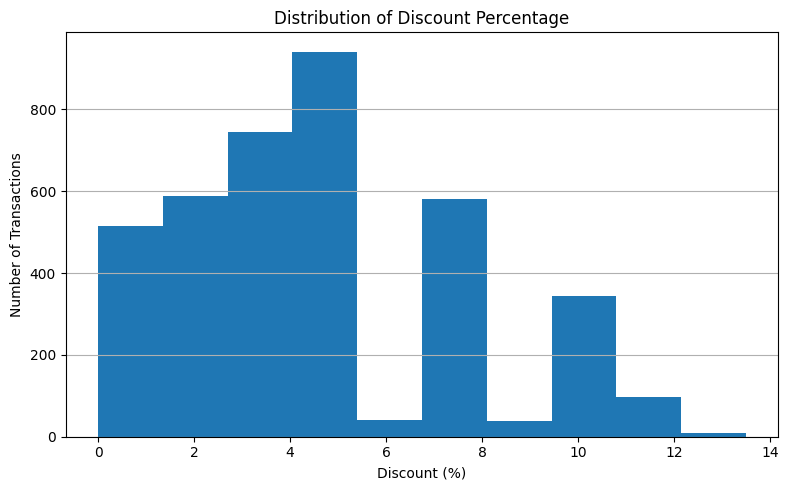

In [31]:
print(df["discount_pct"].describe())

plt.figure(figsize=(8, 5))

plt.hist(
    df["discount_pct"],
    bins=10
)

plt.title("Distribution of Discount Percentage")
plt.xlabel("Discount (%)")
plt.ylabel("Number of Transactions")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

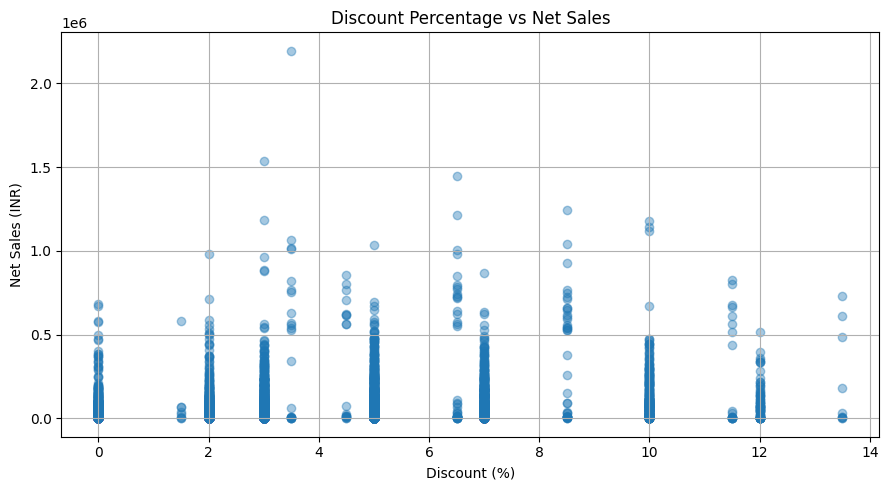

In [32]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["discount_pct"],
    df["net_sales_inr"],
    alpha=0.4
)

plt.title("Discount Percentage vs Net Sales")
plt.xlabel("Discount (%)")
plt.ylabel("Net Sales (INR)")
plt.grid(True)

plt.tight_layout()
plt.show()

# 16. CORRELATION ANALYSIS

In [33]:
correlation_columns = [
    "quantity",
    "unit_price_inr",
    "gross_sales_inr",
    "discount_pct",
    "discount_amount_inr",
    "net_sales_inr",
    "invoice_value_inr_synthetic",
    "lead_time_days",
    "previous_orders"
]

correlation_matrix = df[correlation_columns].corr()

print(correlation_matrix)

                             quantity  unit_price_inr  gross_sales_inr  \
quantity                     1.000000       -0.162566         0.465025   
unit_price_inr              -0.162566        1.000000         0.447948   
gross_sales_inr              0.465025        0.447948         1.000000   
discount_pct                 0.224120        0.010849         0.161232   
discount_amount_inr          0.440267        0.334233         0.861435   
net_sales_inr                0.461741        0.451469         0.999286   
invoice_value_inr_synthetic  0.461741        0.451469         0.999286   
lead_time_days              -0.122266        0.244241         0.123151   
previous_orders              0.004732       -0.003345        -0.006093   

                             discount_pct  discount_amount_inr  net_sales_inr  \
quantity                         0.224120             0.440267       0.461741   
unit_price_inr                   0.010849             0.334233       0.451469   
gross_sales_inr 

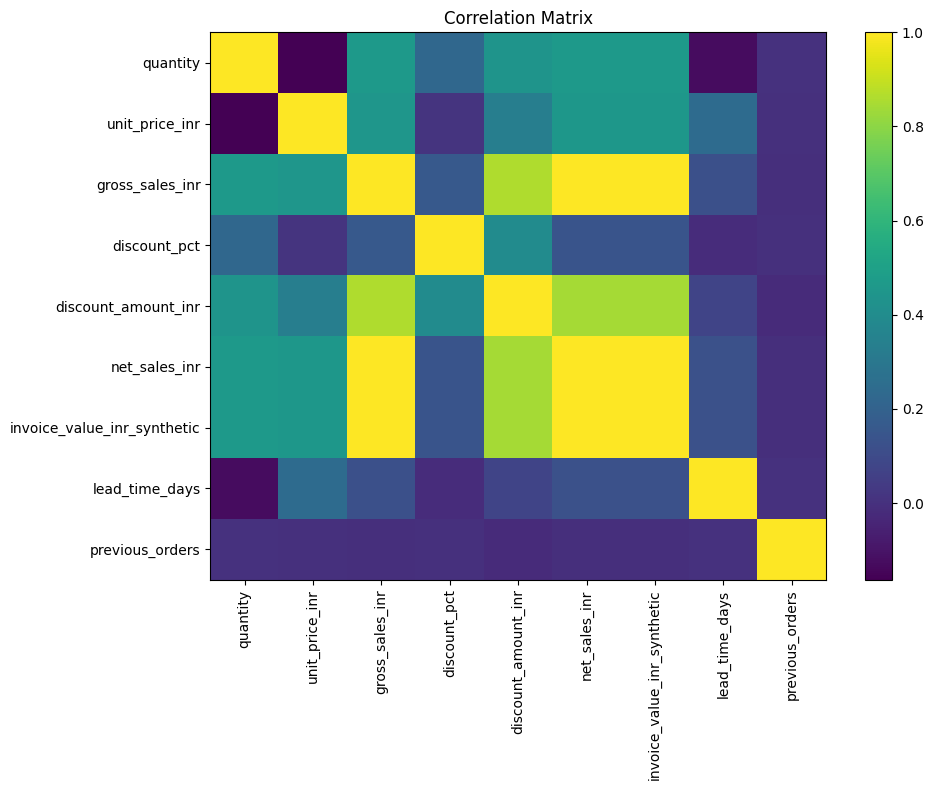

In [34]:
plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

# 17. BUSINESS SUMMARY


In [35]:
print("\n================ BUSINESS SUMMARY ================\n")

print(
    f"Total Net Sales: ₹{df['net_sales_inr'].sum():,.2f}"
)

print(
    f"Total Orders: {df['transaction_id'].nunique():,}"
)

print(
    f"Total Units Sold: {df['quantity'].sum():,}"
)

print(
    f"Average Order Value: ₹{df['net_sales_inr'].mean():,.2f}"
)

print(
    f"Unique Customers: {df['customer_id'].nunique():,}"
)

print(
    f"Average Lead Time: "
    f"{df['lead_time_days'].mean():.2f} days"
)

print(
    f"Top Product Category: "
    f"{category_sales.idxmax()}"
)

print(
    f"Top Brand: "
    f"{brand_sales.idxmax()}"
)

print(
    f"Top Customer City: "
    f"{city_sales.idxmax()}"
)


================ BUSINESS SUMMARY ================

Total Net Sales: ₹384,162,673.55
Total Orders: 3,900
Total Units Sold: 45,263
Average Order Value: ₹98,503.25
Unique Customers: 767
Average Lead Time: 3.33 days
Top Product Category: PV Module
Top Brand: Waaree
Top Customer City: Amravati
